In [1]:
# Code imports
from lib.opt_types import *
from lib.utils import *

# Image inpainting with proximal methods - 30 points + 2 bonus points

Image in-painting consists of reconstructing the missing parts of an image from a given incomplete image.

By exploiting some prior knowledge on the image, it is possible to in-paint images that have a large portion of their pixels missing. In this part of the homework, we are going to study different methods to achieve this goal.

We consider a subsampled image $\mathbf{b} = \mathbf{P}_{\Omega} \mathbf{x}$, where $\mathbf{P}_{\Omega} \in \mathbb{R}^{n \times p}$ is an operator that selects only few, $n \ll p := m^2$, pixels from the vectorized image $\mathbf{x} \in \mathbb{R}^p$. Our goal is to reconstruct the original image $\mathbf{x}$.

### Prior knowledge

Image inpainting is impossible without having some prior knowledge on the structure of the true image $\mathbf{x}$. 

We will explore and compare the following prior assumptions we can make on the true image: 
>  **Assumption**: There exists a orthonormal basis $\mathbf{W} \in \mathbb{R}^{p\times p}$ such that $\mathbf{x}$ can be sparsely represented in that basis, i.e, $\mathbf{W} \mathbf{x}$ is a vector with few non-zero coefficients. Writing $\boldsymbol\alpha=\mathbf W\mathbf x$, we have $\mathbf x=\mathbf W^\top\boldsymbol\alpha$. We promote sparsity by penalizing $\|\boldsymbol\alpha\|_1$, a convex surrogate for the number of nonzero coefficients. We assume that this basis is known and corresponds to the _wavelet basis_. Under this assumption, the reconstruction problem corresponds to solving the following optimization problem:
$$
\min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2}_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
$$
where $\lambda_{\ell_1}$ is a coefficient we will need to choose.



# PART 1: Optimizing with an $\ell_1$ norm regularization

The optimization problem we are looking to solve have an objective function of the form:
$$
	 f(\mathbf{x}) + g(\mathbf{x}).
$$

These types of objectives are referred to as _composite objectives_ where one term, $f$, is smooth and differentiable and the other term $g$ is non-differentiable.

---

## Code structure:

Recall that we have been working with the `Function` type so far. We will augment this type to represent functions that are not differentiable:

- Given a `Function` `g` you can obtain a subgradient at a point `x` by calling `g.subgrad(x)`.

Moreover, since we are dealing with _composite_ problems with a an objective function that can be written `f + g`, we define the `CompositeFunction` type defined as
```python
@dataclass
class CompositeFunction:
    f: Function
    g: Function
```

The iterative schemes you will implement will receive a composite function that they can unpack as follows:

```python
def state_update(composite_function, state):
    f, g = composite_function

```

#### Question 1: (5 point)

A first approach to solve a non-smooth optimization problem can be to turn to subgradients. Review slide 42-44 of Lecture 6, and implement `SubG` with $\alpha_k = \frac{0.1}{\sqrt{k}}$, starting the counter at $k=1$.

In [2]:
@dataclass
class SubG_state(OptState):
    x_k: Vector
    k : int


In [3]:
def SubG_update(composite_function, state):
    x_k, k = state
    f, g = composite_function
    alpha_k = 0.1 / np.sqrt(k)
    d_k = f.grad(x_k) + g.subgrad(x_k)
    x_next = x_k - alpha_k * d_k
    return SubG_state(x_next, k+1)


def SubG_initialize(composite_function, x_zero):
    return SubG_state(x_zero, 1) 


In [4]:
SubG = OptAlgorithm(name="SubG", init_state=SubG_initialize, state_update=SubG_update)

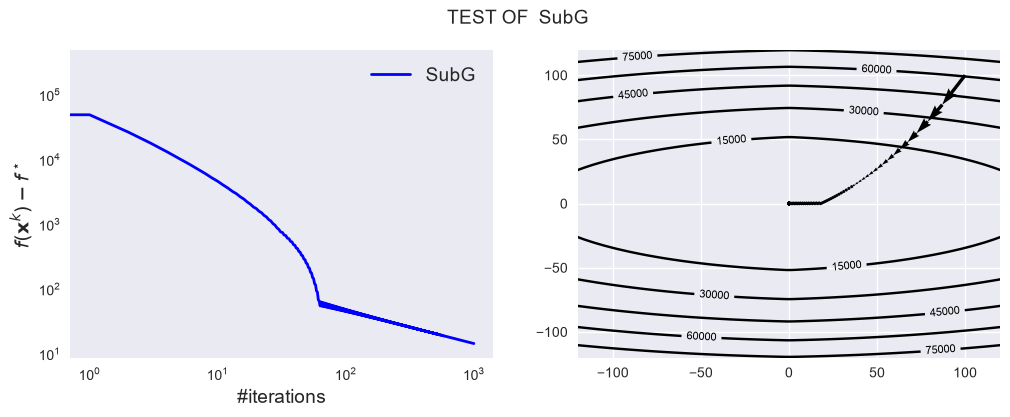

In [5]:
test_composite(SubG)


---

Another, more efficient approach, as we saw in Lecture 8, is to minimize such a function by using proximal gradient algorithms, provided that $g$ is _proximable_ (i.e., its proximal operator is efficient to evaluate). We recall the proximal operator of $g$ as the solution to the following convex problem:
$$
\mathrm{prox}_g(\mathbf{z}) := \mathrm{arg}\min_{\mathbf{y}\in\mathbb{R}^d}\{ g(\mathbf{y}) + \frac{1}{2}\Vert\mathbf{y} - \mathbf{z}\Vert_2^2\}.
$$

#### Question 2 (2 points)

Given $g_{\ell_1}: \mathbb{R}^p \rightarrow \mathbb{R}, \; g_{\ell_1}(\mathbf{x}) :=  \beta \|\mathbf{x}\|_1$ with $\beta\geq0$, show that its proximal function can be written as
    $$
    \mathrm{prox}_{\gamma g_{\ell_1}}(\mathbf{z}) = \max(|\mathbf{z}|-\beta \gamma,0) \circ \mathrm{sign}(\mathbf{z}), \; \text{for any }\mathbf{z} \in \mathbb{R}^p,\; \gamma \in \mathbb{R}_+
    $$
			where the operators $\max$, $\mathrm{sign}$ and $\lvert \cdot \lvert$ are applied coordinate-wise to the vector $\mathbf{z}$ and $\circ$ stands for $(\mathbf{x} \circ \mathbf{y})_i = x_i y_i$. Such a regularizer imposes sparsity on the solutions.


We want to show
$$
\mathrm{prox}_{\gamma g_{\ell_1}}(\mathbf{z}) 
:=
\mathrm{arg}\min_{\mathbf{y}\in\mathbb{R}^p}\{ \gamma \beta \|\mathbf{y}\|_1  + \frac{1}{2}\Vert\mathbf{y} - \mathbf{z}\Vert_2^2\}
=
\max(|\mathbf{z}|-\beta \gamma,0) \circ \mathrm{sign}(\mathbf{z}), \; \text{for any }\mathbf{z} \in \mathbb{R}^p,\; \gamma \in \mathbb{R}_+
$$
element-wise that is 
$$
y_i = \max(|z_i| - \beta \gamma, 0) \mathrm{sign}(z_i) \quad \text{for any }\mathbf{z} \in \mathbb{R}^p,\; \gamma \in \mathbb{R}_+
$$
We can write down the element-wise formulation of the original problem and obtain
$$
\sum_{i=1}^p \gamma \beta |y_i| + \frac{1}{2} \sum_{i=1}^p (y_i - z_i)^2
$$
notice that all elements are independent, so we can optimize element-wise
$$
y_i = \mathrm{arg}\min_{u \in \R} \gamma \beta |u| + \frac{1}{2}(u - z_i)^2
$$
this is solvable with classical tools when $u \neq 0$. In particular, once we fix the sign of $u$, we obtain  
$$
u \geq 0 \implies f(u) = \gamma \beta u + \frac{1}{2} (u - z_i)^2
$$
is a quadratic with positive second degree coefficient, with minimum (found eg. by differentiating) in 
$$
y_{i, +} = - \gamma \beta + z_i 
$$
notice that $y_{i, +}$ is not allowed to be negative, but because of the functional shape we know that whenever $- \gamma \beta + z_i < 0$ the minimum in $[0, \infty)$ is in $0$. Therefore we obtain
$$
y_{i, +} = \max(- \gamma \beta + z_i, 0)
$$ 
Analogously we obtain
$$
u \leq 0 \implies f(u) = -\gamma \beta u + \frac{1}{2} (u - z_i)^2 \\
\implies y_{i, -} = \gamma \beta + z_i
$$
and by the same reasoning as above, whenever $\gamma \beta + z_i > 0$, the minimum in $(-\infty, 0]$ is in $0$. Therefore we obtain
$$
y_{i, -} = \min(\gamma \beta + z_i, 0) = -\max(-\gamma \beta -z_i, 0)
$$
Our result is algebraically equivalent to the assignment, as (depending on the sign of $z_i$) one of $y_{i, +}, y_{i, -}$ is always evaluating to 0, because $\gamma, \beta$ are assumed to be positive. Therefore the only meaningful check is 
$$
y_i = \max(-\gamma \beta + |z_i|, 0) \mathrm{sign}(z_i)
$$

#### Question 3 (1 point)
 Fill in the function `l1_prox` with the proximal operator of $g_{\ell_1}$.

In [6]:
def l1_prox(gamma, z, beta):
    return np.sign(z) * np.maximum(np.abs(z) - gamma * beta, 0.0)

#### Question 4 (4 points)

From here on, in order to speed-up the convergence of the optimization, let's assume that the function $f$ has been made to be $\mu$-strongly convex by the addition of an $\ell_2$ regularization term to the function $f$, while the $\ell_1$ term, $g$, has remained unchanged. As such, we must now utilize the strong-convexity versions of the composite optimization algorithms.

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{ISTA}_\mu$. In the provided quadratic test, $\beta=30$. Use `g.prox(alpha, z)` to apply the proximal operator of the supplied regularizer, including its weight.

In [7]:
@dataclass
class ISTA_state(OptState):
    x_k: Vector
    alpha_k : float

In [8]:
def ISTA_update(composite_function, state):
    f, g = composite_function
    x_k, alpha_k = state
    z = x_k - alpha_k * f.grad(x_k)
    x_next = g.prox(alpha_k, z)
    return ISTA_state(x_next, alpha_k)

def ISTA_initialize(composite_function, x_zero):
    f, g = composite_function
    alpha_zero = 2 / (f.lips_grad + f.strng_cvx)
    return ISTA_state(x_zero, alpha_zero)


In [9]:
ISTA = OptAlgorithm(name="ISTA", init_state= ISTA_initialize, state_update=ISTA_update)

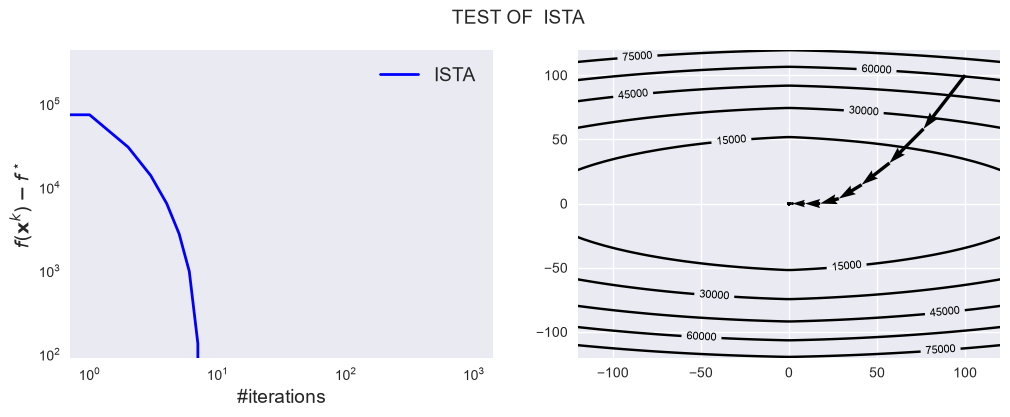

In [10]:
test_composite(ISTA, prox=l1_prox)


#### Question 5  (7 points)

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{FISTA}_\mu$.

In [11]:
@dataclass 
class FISTA_state(OptState):
    x_k: Vector
    y_k: Vector
    alpha_k: float
    c_f: float
    pass


In [12]:
import numpy

def FISTA_update(composite_function, state):
    f, g = composite_function
    x_k, y_k, alpha_k, c_f = state
    z = y_k - alpha_k * f.grad(y_k)
    x_next = g.prox(alpha_k, z)
    y_next = x_next + (np.sqrt(c_f) - 1)/(np.sqrt(c_f) + 1) * (x_next - x_k)
    return FISTA_state(x_next, y_next, alpha_k, c_f)

def FISTA_initialize(composite_function, x_zero):
    f, g = composite_function
    alpha_zero = 1/f.lips_grad
    c_f = f.lips_grad/f.strng_cvx
    return FISTA_state(x_zero, x_zero, alpha_zero, c_f)


In [13]:
FISTA = OptAlgorithm(name="FISTA", init_state= FISTA_initialize, state_update=FISTA_update)

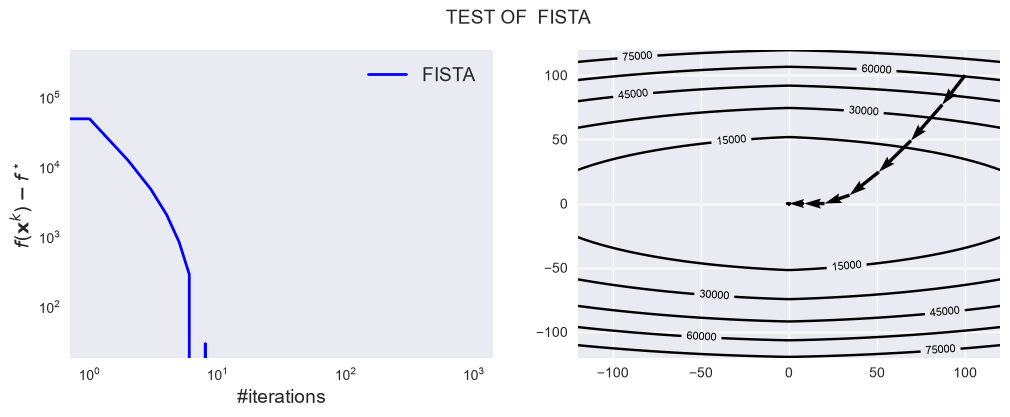

In [14]:
test_composite(FISTA, prox=l1_prox)


#### Question 6  (2 points)

Compare the convergence rates of the three methods and analyze whether the observed results align with their theoretical bounds.

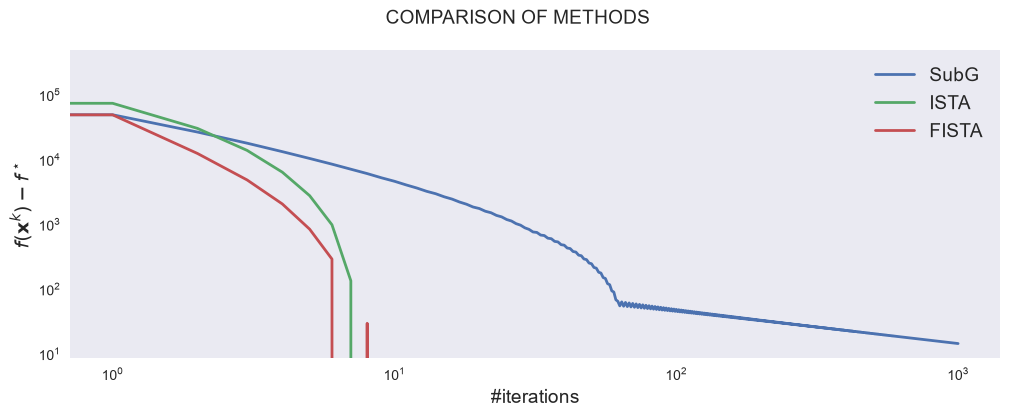

In [15]:
list_of_methods = [SubG, ISTA, FISTA]
compare_composite(list_of_methods, prox=l1_prox)


# TODO

1) dire qualcosa sul fatto che FISTA non è monotono
2) confrontare le convergenze  


# Part 2: Application


We have now implemented multiple methods that can solve composite optimization problems. We will now apply them to an image inpainting problem.


Take a natural image, or better a picture of you, and place it in the same directory as this notebook.

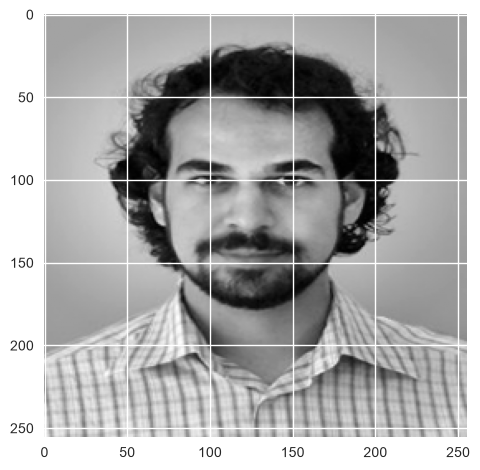

In [16]:
from lib.inpainting import *

image = load("lib/alp.jpg")  # FILL: replace with your image filename. #TODO

With this image in hand, let us subsample it and try to reconstruct the original.

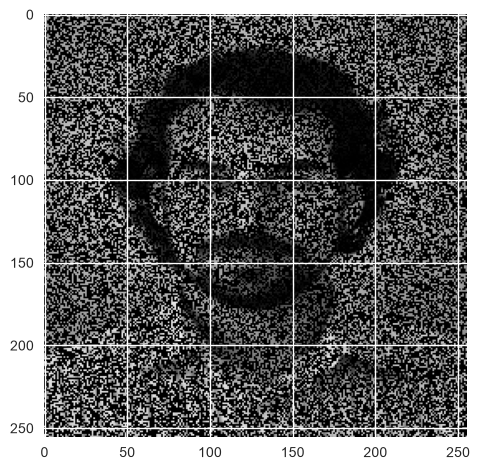

In [17]:
subsampled = show_subsampled(image)

For the rest of the questions, to ensure the function is 
$\mu$-strongly convex, we need to add an $\ell_2$ regularization term to it. As a result, we change the definition of $f_{\ell_1}(\mathbf{\alpha})$ as follows:
$$
    f_{\ell_1}(\mathbf{\alpha}) = \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 
    $$

and the composite function becomes:
 $$
    \min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 }_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
    $$

By adding this regularization, we ensure better properties for optimization, making the solution more stable and well-behaved.

In the following cells we will define the optimization problems we need to solve to perform the reconstruction.

- We provide you with a function `P` that acts like the matrix $\mathbf{P}_{\Omega}$. That is, given a vector `x`, it returns a subsampled vector `P(x)` that corresponds to $\mathbf{P}_{\Omega} \mathbf{x}$. We also give you `P_T` which acts like $\mathbf{P}^\top$.
- We provide you with a function `W` and `W_T` that act like the matrix $\mathbf{W}$ and $\mathbf{W^\top}$ respectively. That is, for a vector `x`, `W(x)` and `W_T(x)` return $\mathbf{W}\mathbf{x}$ and $\mathbf{W^\top}\mathbf{x}$ respectively.

__(a)__ (1 point) Using these provided functions, define the observed variable `b` in the cell below.

In [18]:
from lib.inpainting import P, P_T, W, W_T

x = image.reshape(-1) #flattened image

b = P(x)

__(b)__ (1 point) Now define the function `f_l1` as described earlier in the problem text.

In [19]:
mu = 1e-4 # Desired strong convexity of f
def f_l1(alpha):
    return 0.5 * np.linalg.norm(b - P(W_T(alpha)))**2 + 0.5 * mu * np.linalg.norm(alpha)**2


__(c)__ (1 point) Write the gradient of $f_{\ell_1}(\mathbf{\alpha})$.

In [20]:
def grad_f_l1(alpha):
    return -W(P_T(b - P(W_T(alpha)))) + mu * alpha

__(d)__ (1 points) Find the Lipschitz constant of $\nabla_\mathbf{\alpha} f_{\ell_1}(\mathbf{\alpha})$ analytically and fill it in the cell below. 

we have 
$$
\begin{align*}
\nabla f_{l_1}(\alpha) 
&= -W P^T (b - P W^T \alpha) + \mu \alpha \\
&= -W P^T b + W P^T P W^T \alpha + \mu \alpha \\
\end{align*}
$$
We can compute the Lipschitz constant by checking when the following function is convex 
$$
h(\alpha) = \frac{L}{2} \|\alpha\|_2^2 - f_{l_1}(\alpha)
$$
and since the gradient is itself differentiable, we can  differentiate twice and check if the hessian is positive semi-definite
$$
H = L \mathbf{I} - W P^T P W^T - \mu \mathbf{I} \\ 
$$
notice that, since $W$ is orthogonal, $W^T = W^{-1}$. Therefore $W P^T P W^T$ has the same eigenvalues as $P^T P$ which only has eigenvalues equal to $0$ or $1$. To ensure that all eigenvalues are non-negative we need 
$$
L - \mu \geq 1 \implies L \geq \mu + 1
$$
Therefore the optimal Lipschitz constant is
$$
L = \mu + 1
$$

In [ ]:
lips_grad_f_l1 = mu + 1

We have all the necessary ingredients to define the smooth part of our composite objective:

In [22]:
f_l1 = Function(f = f_l1, grad=grad_f_l1, lips_grad = lips_grad_f_l1, strng_cvx=mu)

For the non-smooth term, `l1` represents the unweighted $\ell_1$ norm. `Regularizer` applies the weight `lmda` to both the function value and its proximal operator, reusing `l1_prox` with $\beta=1$:

In [23]:
l1 = Function(f = lambda x: np.sum(np.abs(x), axis=0), prox=lambda gamma, z: l1_prox(gamma, z, beta=1))

g_l1 = Regularizer(l1)

In [24]:
composite_objective = CompositeFunction(f=f_l1, g=g_l1)

With the objective defined, we provide you with a function with the following signature:
```python
solve_composite(method: OptAlgorithm, composite_objective: CompositeFunction, lmda: float, max_iterations: int) -> Vector
```

In other words, the function takes an optimization algorithm `method`, a CompositeFunction `composite_objective`, a regularization parameter `lmda` and a number of iterations `max_iterations` and returns a vector which is the last iterate given by the `method`.



In [25]:
from lib.inpainting import solve_composite

__(e)__ (5 points) Using `solve_composite` reconstruct the subsampled image. Recall that the composite problem solves for $\mathbf{\alpha}$ so you need to convert the output back to an image and visualize it.

Select a reasonable value for `lmda`.

**Bonus (2 points).** Using `solve_composite` and the `PSNR` metric, find the best value for `lmda`.

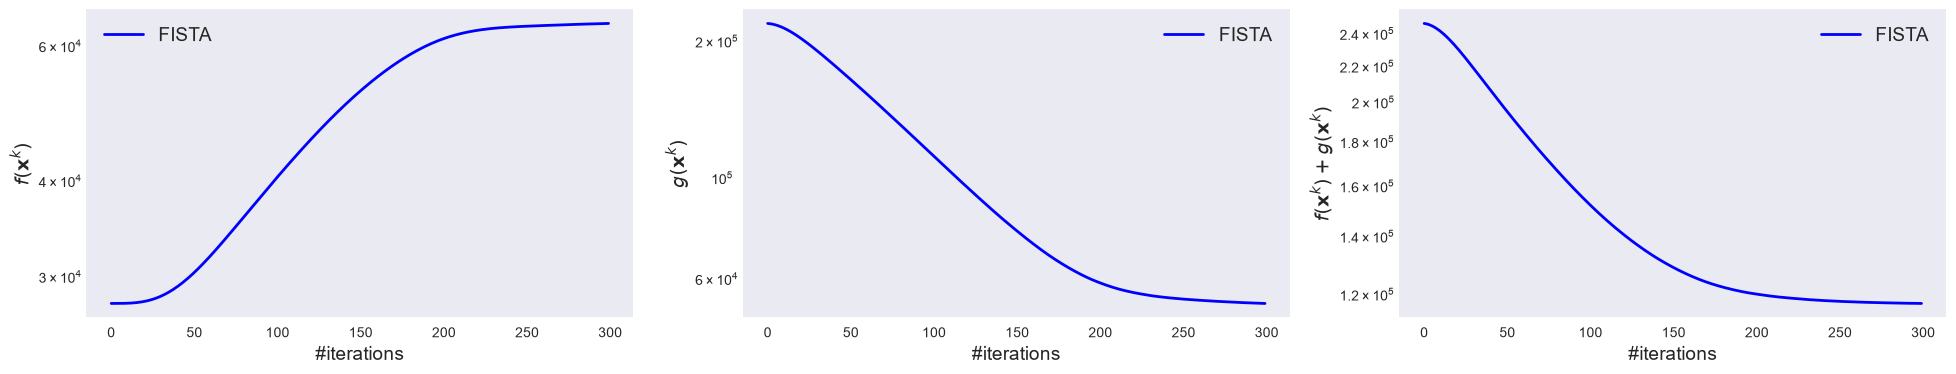

In [26]:
lmda = 5e-2 + 8e-3 #TODO capire cosa è ragionevole
out = solve_composite(FISTA, composite_objective, lmda, 300)
flat_image_out = W_T(out)
image_out = flat_image_out.reshape(m, m)


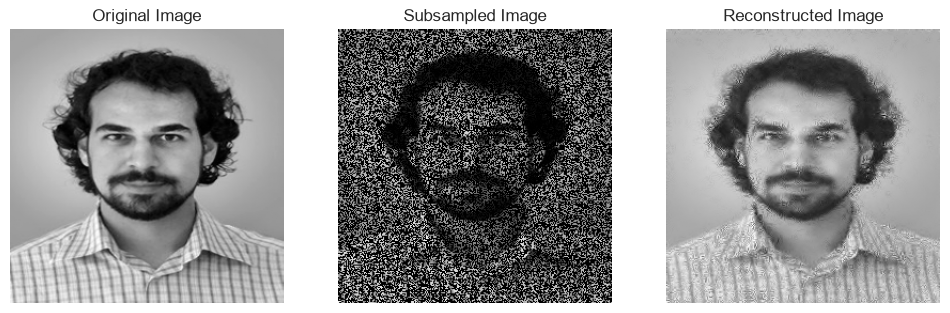

In [27]:
show(true = image, subsampled=subsampled, estimated=image_out)

In [28]:
# FILL: optional bonus parameter search using PSNR.
# TODO, capire cos'è PSNR. In giro trovo log(cost/MSE) quindi posso massimizzare l'MSE